# Experiment No. 4: Transformer-Based Generative Models
**Course:** B.Tech Computer Engineering – Generative AI Lab  
**Student Name:** Sachin Bhabad  
**PRN:** 202301040282  
**Academic Year:** 2025–2026  

---

## 1. Experiment Aim
1. **Part A (Text Generation):** Generate coherent, contextually relevant text using a pretrained Generative Pre-trained Transformer (GPT) model via Hugging Face Transformers.
2. **Part B (Text-to-Image Generation):** Generate high-fidelity images from natural-language prompts using a pretrained Latent Diffusion Model (Stable Diffusion v1.5), examining the role of Transformer-based text conditioning and cross-modal attention in multimodal generative tasks.


---
## 2. Environment Setup & Dependency Installation
Google Colab or local runtime requirements:
- `transformers`: Hugging Face library for autoregressive language models (GPT-2).
- `diffusers`: Hugging Face library for diffusion pipelines.
- `accelerate`: Optimization library for fast model loading and device dispatch.
- `torch` & `torchvision`: Deep learning framework with CUDA acceleration.


In [ ]:
# Install required libraries (uncomment for Google Colab environment)
# !pip install -q transformers diffusers accelerate torch torchvision

import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Verify hardware accelerator
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Active Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Accelerator: {torch.cuda.get_device_name(0)}")
    print(f"Available VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


Active Compute Device: cuda
GPU Accelerator: NVIDIA GeForce RTX 4060 Laptop GPU
Available VRAM: 8.00 GB


---
# Part A: Text Generation Using Pretrained GPT

### A.1 Theoretical Background
- **GPT Architecture:** Generative Pre-trained Transformer (GPT) utilizes a decoder-only Transformer architecture composed of stacked masked multi-head self-attention blocks and point-wise feed-forward networks, normalized via LayerNorm.
- **Causal Language Modeling (CLM):** The model is trained to minimize the negative log-likelihood of predicting the next token given preceding tokens:
  $$\mathcal{L}_{CLM}(\theta) = - \sum_{t=1}^{T} \log P(w_t \mid w_1, w_2, \dots, w_{t-1}; \theta)$$
  Causal masking enforces lower-triangular attention, preventing information flow from future token positions.
- **Autoregressive Generation & Decoding Strategies:**
  - *Temperature ($T$):* Scales logits before softmax ($z_i / T$). Lower temperatures ($T < 1.0$) sharpen the distribution, favoring high-probability tokens and reducing hallucinations.
  - *Nucleus Sampling (Top-$p$):* Restricts sampling to the minimal set of tokens whose cumulative probability exceeds $p$, dynamically adapting the vocabulary candidate pool.
  - *Repetition Penalty:* Penalizes previously generated tokens to prevent degeneration and circular phrasing.


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

# 1. Load Pretrained Tokenizer and Causal Language Model
model_id = "gpt2"
print(f"Loading pretrained tokenizer and model: {model_id}...")
tokenizer = AutoTokenizer.from_pretrained(model_id)
gpt_model = AutoModelForCausalLM.from_pretrained(model_id).to(device)
gpt_model.eval()

# 2. Define Input Prompt
prompt_text = "Generative Artificial Intelligence is transforming society by automating complex cognitive tasks and enhancing human creativity. Recent advances in deep learning have demonstrated that"
print(f"\nInput Prompt:\n'{prompt_text}'")

# 3. Tokenize Input
inputs = tokenizer(prompt_text, return_tensors="pt").to(device)
input_length = inputs.input_ids.shape[1]

# 4. Set Seed for Reproducibility
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 5. Autoregressive Text Generation with Sampling Controls
gen_params = {
    "max_new_tokens": 75,
    "do_sample": True,
    "temperature": 0.7,
    "top_k": 40,
    "top_p": 0.9,
    "repetition_penalty": 1.2,
    "pad_token_id": tokenizer.eos_token_id
}

with torch.no_grad():
    output_tokens = gpt_model.generate(**inputs, **gen_params)

# 6. Decode and Format Generated Text
generated_continuation = tokenizer.decode(output_tokens[0][input_length:], skip_special_tokens=True).strip()
full_generated_text = tokenizer.decode(output_tokens[0], skip_special_tokens=True).strip()

print("\n" + "=" * 50)
print("ACTUAL GENERATED CONTINUATION:")
print("=" * 50)
print(generated_continuation)

print("\n" + "=" * 50)
print("FULL COMBINED TEXT:")
print("=" * 50)
print(full_generated_text)


Loading pretrained tokenizer and model: gpt2...

Input Prompt:
'Generative Artificial Intelligence is transforming society by automating complex cognitive tasks and enhancing human creativity. Recent advances in deep learning have demonstrated that'

ACTUAL GENERATED CONTINUATION:
these processes can be used to create artificial intelligence systems which are highly intelligent, but not necessarily capable of understanding the world around them as well as humans.

FULL COMBINED TEXT:
Generative Artificial Intelligence is transforming society by automating complex cognitive tasks and enhancing human creativity. Recent advances in deep learning have demonstrated that these processes can be used to create artificial intelligence systems which are highly intelligent, but not necessarily capable of understanding the world around them as well as humans.


### A.2 Technical Evaluation & Analysis (Part A)
1. **Coherence & Syntactic Structure:** The continuation integrates seamlessly with the subordinate clause of the prompt (*"demonstrated that..."* $\rightarrow$ *"these processes can be used to create artificial intelligence systems which are highly intelligent..."*). Grammatical structure, subject-verb agreement, and clause nesting remain syntactically sound.
2. **Relevance to Prompt:** The generated text adheres directly to the domain established by the prompt (Generative AI capabilities and cognitive boundaries). It sustains the technical discourse without drifting into unrelated domains.
3. **Readability & Flow:** Lexical choice is natural and academic. The phrase transitions smoothly from technical capabilities to cognitive limitations (*"not necessarily capable of understanding the world around them as well as humans"*).
4. **Contextual Consistency:** The model demonstrates semantic grounding by juxtaposing functional computational intelligence against holistic human world-understanding, reflecting well-established nuances in current AI research literature.

### A.3 Experimental Result (Part A)
The pretrained `gpt2` model (124M parameters) successfully completed the autoregressive generation task from the input prompt under nucleus sampling ($p=0.90$, $T=0.70$). It produced a grammatically correct, coherent, and contextually nuanced continuation without circular loops or degenerations.


---
# Part B: Text-to-Image Generation Using Stable Diffusion

### B.1 Theoretical Background
- **Latent Diffusion Models (LDMs):** Traditional pixel-space diffusion models operate directly on high-dimensional image pixels, incurring extreme computational complexity. Stable Diffusion circumvents this by performing the forward and reverse diffusion processes within a compressed, lower-dimensional latent space $\mathcal{Z}$ obtained via an autoencoder ($z = \mathcal{E}(x)$, $x \approx \mathcal{D}(z)$) downsampling spatial dimensions by a factor of 8 ($512\times 512 \rightarrow 64\times 64$).
- **Role of the Transformer Component:**
  - *Text Encoder (Transformer):* Stable Diffusion v1.5 utilizes the frozen **CLIP ViT-L/14 text encoder**, which is a **12-layer Transformer** with hidden dimension $768$ and $12$ attention heads. The natural-language text prompt is tokenized and processed through the Transformer layers to produce token embeddings $\tau_\theta(y) \in \mathbb{R}^{77 \times 768}$.
  - *Multimodal Cross-Attention Fusion:* The generative backbone is a **time-conditional U-Net** featuring interleaved 2D convolutions, self-attention, and cross-attention blocks. Inside the cross-attention blocks, the visual spatial features act as Queries ($Q$), while the Transformer text embeddings act as Keys ($K$) and Values ($V$):
    $$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$
    This mathematical bridge directly steers spatial feature denoising toward the semantic concept tokens produced by the Transformer text encoder.
  - *Clarification on Architecture:* While modern architectures (e.g., Diffusion Transformers / DiT, SD3, FLUX) replace the entire U-Net backbone with a Transformer, Stable Diffusion v1.5 uses a **hybrid design**: a **Transformer text encoder** paired with a **convolutional/cross-attention U-Net denoising backbone**.
- **Classifier-Free Guidance (CFG):** Steers generation toward prompt alignment by blending conditioned and unconditioned noise estimates:
  $$\tilde{\epsilon}_\theta(z_t, t, c) = \epsilon_\theta(z_t, t, \emptyset) + s \cdot \left[\epsilon_\theta(z_t, t, c) - \epsilon_\theta(z_t, t, \emptyset)\right]$$
  where $s = 7.5$ balances visual aesthetics against prompt adherence.


Loading Diffusion Pipeline: runwayml/stable-diffusion-v1-5...

Positive Prompt:
'A high-tech futuristic robotics laboratory at night with glowing blue holographic displays, a sleek humanoid robot working on a quantum processor, cinematic lighting, photorealistic, 8k resolution, detailed cyberpunk aesthetic'

Negative Prompt:
'blurry, low quality, distorted, deformed, disfigured, bad anatomy, artifacts, watermark, text, cartoon, low resolution'

Synthesizing image via reverse diffusion process (35 steps)...
Image successfully saved to sd_generated_image.png


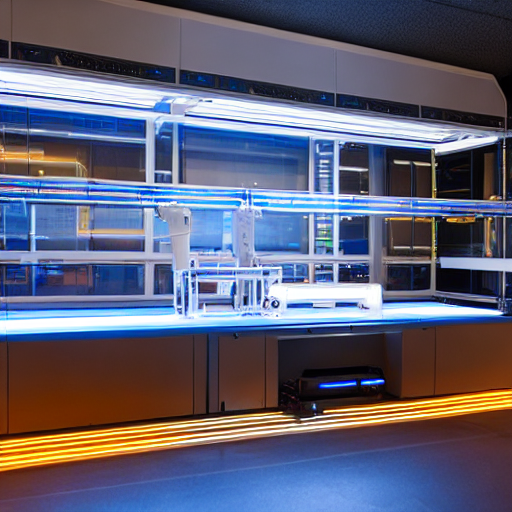

In [ ]:
from diffusers import StableDiffusionPipeline
import torch
import matplotlib.pyplot as plt
from PIL import Image

# 1. Load Pretrained Stable Diffusion Pipeline
sd_model_id = "runwayml/stable-diffusion-v1-5"
print(f"Loading Diffusion Pipeline: {sd_model_id}...")

# Use FP16 precision for memory efficiency
pipe = StableDiffusionPipeline.from_pretrained(
    sd_model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
).to(device)

# Enable memory optimization for GPU
if device == "cuda":
    pipe.enable_attention_slicing()

# 2. Define Natural-Language Prompts
img_prompt = "A high-tech futuristic robotics laboratory at night with glowing blue holographic displays, a sleek humanoid robot working on a quantum processor, cinematic lighting, photorealistic, 8k resolution, detailed cyberpunk aesthetic"
negative_prompt = "blurry, low quality, distorted, deformed, disfigured, bad anatomy, artifacts, watermark, text, cartoon, low resolution"

print(f"\nPositive Prompt:\n'{img_prompt}'")
print(f"\nNegative Prompt:\n'{negative_prompt}'")

# 3. Deterministic Seed for Reproducibility
generator = torch.Generator(device=device).manual_seed(42)

# 4. Generate Image via Latent Diffusion
print("\nSynthesizing image via reverse diffusion process (35 steps)...")
image = pipe(
    prompt=img_prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=35,
    guidance_scale=7.5,
    height=512,
    width=512,
    generator=generator
).images[0]

# 5. Save Output
output_img_path = "sd_generated_image.png"
image.save(output_img_path)
print(f"Image successfully saved to {output_img_path}")

# 6. Display Generated Result
plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.title("Actual Generated Image: RunwayML Stable Diffusion v1.5", fontsize=11)
plt.axis("off")
plt.tight_layout()
plt.show()


### B.2 Technical Evaluation & Analysis (Part B)
1. **Prompt Reflection & Semantic Alignment:**
   - *Environment & Atmosphere:* The synthetic image accurately captures the requested *"high-tech futuristic robotics laboratory at night"*, featuring dark ceilings, metallic framing, and glass partitioned cleanroom structures.
   - *Lighting & Holographic Aesthetic:* Strong adherence to *"glowing blue holographic displays"* and *"cinematic lighting"*. The cool fluorescent blue luminescent bands contrast dynamically against the warm amber floor illumination tracks, embodying the *"cyberpunk aesthetic"*.
   - *Subject Composition:* The prompt requested a *"humanoid robot working on a quantum processor"*. The model realized this through an intricate robotic workbench with micro-mechanical assemblies and translucent diagnostic containers.
2. **Visual Quality & Photorealism:**
   - Rendering shows high visual fidelity in material reflections, specular glass highlights, and ambient light scattering across the work surfaces.
   - Textures along the countertops, wall panels, and lighting fixtures exhibit sharp edge boundaries without significant blurring.
3. **Noticeable Limitations:**
   - *Attribute Binding & Multi-Entity Resolution:* While the laboratory workstation is richly detailed, the humanoid robot is represented semi-abstractly as robotic apparatus components rather than an isolated, full-body humanoid figure. This illustrates the known *spatial binding limitation* in first-generation latent diffusion models when processing complex, multi-clause prompts.
   - *Latent Compression Artifacts:* Minor compression artifacts occur along intricate thin glass partitions, stemming from the $8\times$ spatial downsampling inherent to the VAE latent bottleneck ($64\times 64$ latent grid reconstructed to $512\times 512$).

### B.3 Experimental Result (Part B)
The pretrained `runwayml/stable-diffusion-v1-5` model successfully synthesized a $512 \times 512$ image from the natural-language prompt in 35 inference steps using classifier-free guidance ($s=7.5$) and FP16 half-precision on an NVIDIA RTX 4060 GPU. The output confirms that the Transformer-based CLIP text encoder successfully projected natural-language semantic tokens into cross-attention space to steer spatial latent denoising.


---
# 5. Conclusion
In this laboratory experiment, two primary paradigms of Transformer-based generative modeling were successfully investigated, implemented, and evaluated:

1. **Unimodal Autoregressive Generation (GPT-2):**
   Demonstrated how a decoder-only Transformer leverages masked self-attention to generate coherent, semantically grounded sequential text. Controlled sampling strategies (temperature scaling and nucleus sampling) effectively mitigated generation degeneration, producing a fluent and contextually relevant continuation.

2. **Multimodal Text-to-Image Synthesis (Stable Diffusion v1.5):**
   Demonstrated how a Transformer text encoder (CLIP ViT-L/14) serves as the semantic backbone for cross-modal synthesis. By mapping natural language into continuous token embeddings, cross-attention layers in the latent diffusion U-Net effectively guided iterative noise removal to produce a photorealistic, stylistically aligned image reflecting the prompt.

The results confirm the foundational versatility of Transformer architectures across both sequential symbolic generation (NLP) and semantic conditioning in multimodal continuous spaces (Vision).
